# 01 · The xLAM-60k dataset

This notebook gets to know [Salesforce/xlam-function-calling-60k](https://huggingface.co/datasets/Salesforce/xlam-function-calling-60k), the data every model in this project is trained and evaluated on, and builds the train / validation / test split.

It answers four questions:

1. **What does a task look like?** How many calls, tools and arguments.
2. **How varied is it?** How many distinct tools, and how often each is used.
3. **How clean are the labels?** Duplicates, contradictions, and labels a model can't reasonably produce.
4. **How should we split it?** And does the split keep the distributions intact.

The logic lives in `fc_distill.data`, `fc_distill.quality`, `fc_distill.splits` and `fc_distill.eda`, all unit-tested; this notebook only calls it and tells the story. Decisions it relies on: [ADR 0001](../docs/adr/0001-train-validation-test-split.md) (three splits) and [ADR 0002](../docs/adr/0002-test-labels-never-edited.md) (validation and test are never edited).

In [1]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # no ipywidgets: plain progress

In [2]:
import json
from collections import Counter
from pathlib import Path

import pandas as pd

from fc_distill import eda, quality, splits
from fc_distill.data import DATASET, DATASET_REVISION, load_all

pd.set_option("display.max_colwidth", 120)
examples = load_all()
print(f"{DATASET} @ {DATASET_REVISION[:7]}: {len(examples):,} rows")

Salesforce/xlam-function-calling-60k @ 26d14eb: 60,000 rows


## 1. One example

Each row is a user **query**, the **tools** the model may call (name, description, typed parameters), and the gold **answers**: the list of calls that satisfies the query. The dataset was generated by Salesforce's APIGen pipeline and every answer was checked by executing it, which shows in the structure: every row parses (`load_all` would raise otherwise), and every call names an offered tool with declared arguments, as the cell below checks. The two structural train filters planned in #6, unparseable answers and calls to unknown functions, therefore remove no rows.

In [3]:
ex = examples[0]
print("QUERY  ", ex["query"])
print("TOOLS  ", json.dumps(ex["tools"], indent=1)[:700], "...")
print("ANSWER ", json.dumps(ex["answers"]))

QUERY   Where can I find live giveaways for beta access and games?
TOOLS   [
 {
  "name": "live_giveaways_by_type",
  "description": "Retrieve live giveaways from the GamerPower API based on the specified type.",
  "parameters": {
   "type": {
    "description": "The type of giveaways to retrieve (e.g., game, loot, beta).",
    "type": "str",
    "default": "game"
   }
  }
 }
] ...
ANSWER  [{"name": "live_giveaways_by_type", "arguments": {"type": "beta"}}, {"name": "live_giveaways_by_type", "arguments": {"type": "game"}}]


In [4]:
problems = quality.unknown_calls(examples)
print(f"calls to tools that aren't offered, or with undeclared arguments: {len(problems)}")
assert not problems

calls to tools that aren't offered, or with undeclared arguments: 0


## 2. The shape of a task

How many calls does a query need, and what kind? *Parallel* means the same function called several times (weather in three cities), *multiple* means different functions, *mixed* means both.

,calls,tools_offered,arguments,query_chars
count,60000.0,60000.0,60000.0,60000.0
mean,1.7,2.8,2.8,111.9
std,0.9,1.6,1.9,57.6
min,1.0,1.0,0.0,16.0
25%,1.0,1.0,2.0,72.0
50%,2.0,3.0,2.0,100.0
75%,2.0,4.0,4.0,136.0
max,52.0,8.0,104.0,1330.0


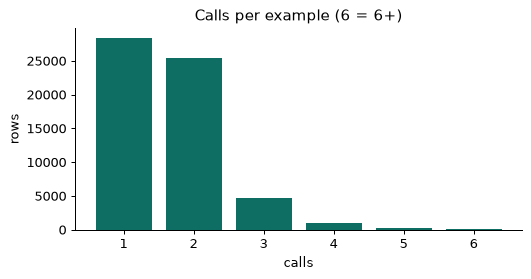

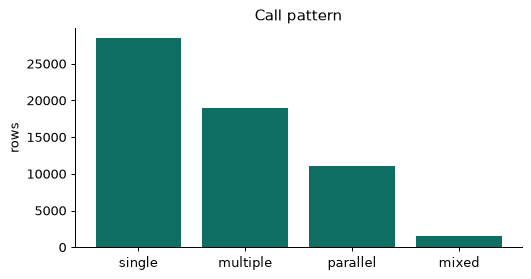

In [5]:
stats = pd.DataFrame(eda.example_stats(examples))
patterns = Counter(eda.call_pattern(ex) for ex in examples)
eda.plot_counts(Counter(stats["calls"].clip(upper=6)), "Calls per example (6 = 6+)", "calls")
eda.plot_counts(patterns, "Call pattern", "")
stats[["calls", "tools_offered", "arguments", "query_chars"]].describe().round(1)

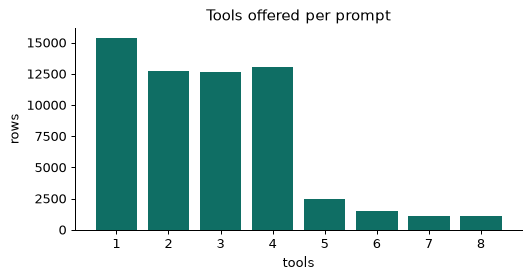

In [6]:
eda.plot_counts(Counter(stats["tools_offered"]), "Tools offered per prompt", "tools");

About half the rows need a single call; the rest need two or more, mostly *parallel* or *multiple*. Every prompt offers between one and a handful of tools, so the model must both **pick** the right tools and **fill** their arguments, sometimes several times.

## 3. Tools and parameter types

How many distinct tools appear, and is usage spread evenly or dominated by a few?

3,179 distinct functions called; top 10:


,function,calls
0,search,1469
1,loginuser,458
2,calculate_standard_deviation,408
3,calculate_investment_return,383
4,is_perfect_square,369
5,is_sum_of_cubes,366
6,is_power_of_two,362
7,find_n_largest_numbers,354
8,sort_numbers,352
9,get_ip_zipcode,352


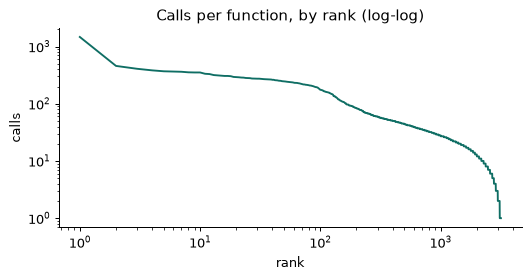

In [7]:
called = eda.called_function_counts(examples)
print(f"{len(called):,} distinct functions called; top 10:")
display(pd.DataFrame(called.most_common(10), columns=["function", "calls"]))
eda.plot_rank_frequency(called, "Calls per function, by rank (log-log)");

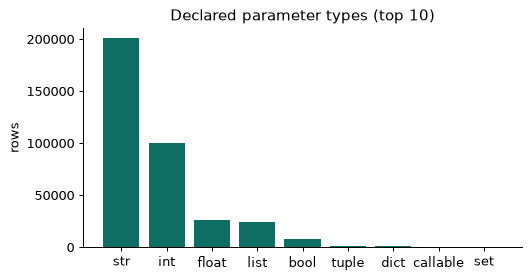

In [8]:
types = eda.declared_type_counts(examples)
eda.plot_counts(Counter(dict(types.most_common(10))), "Declared parameter types (top 10)", "");

Usage has a **long tail**: a few utility functions (math, unit conversion) are very common, while thousands of API wrappers appear only a handful of times. Most parameters are strings and integers, but lists, tuples and even `Callable` parameters exist, and those are where models have to produce structured or code-like values.

## 4. Lengths in tokens

Measured with the Qwen3.5 tokenizer and the exact chat template the models see, on a random sample of 5,000 rows. These numbers set `max_model_len` for inference and the sequence length for training.

,p50,p90,p99,max
prompt,471,915,1440,3525
answer,45,80,139,912


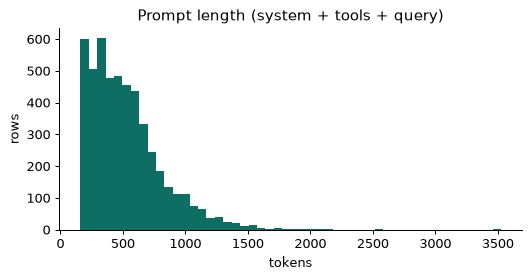

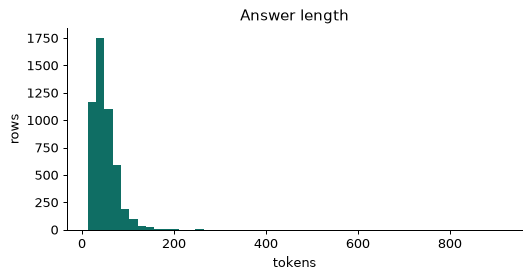

In [9]:
import random

sample = random.Random(0).sample(examples, 5000)
prompt_tokens, answer_tokens = eda.token_lengths(sample)
lengths = {"prompt": eda.percentiles(prompt_tokens), "answer": eda.percentiles(answer_tokens)}
display(pd.DataFrame(lengths).T)
eda.plot_hist(prompt_tokens, "Prompt length (system + tools + query)", "tokens")
eda.plot_hist(answer_tokens, "Answer length", "tokens");

Prompts are dominated by the tool definitions, and answers are short, so training cost is mostly *reading* prompts, not generating answers. The tail is long, though: a 52-call answer runs to about 2,000 tokens. Outliers are kept; they are too few to matter for training. Inference limits are set from every validation and test row, not this sample, in section 6.

## 5. Label quality

The rows are structurally valid, but that doesn't make every label one a model can reasonably match. Each check below comes from `fc_distill.quality` and only reports; section 6 decides what to do.

### 5a. Duplicates

In [10]:
dups = quality.exact_duplicates(examples)
norm = Counter(quality.normalize_query(ex["query"]) for ex in examples)
print(f"exact duplicate rows (beyond the first copy): {sum(len(g) - 1 for g in dups):,}")
print(f"rows whose query text appears more than once: {sum(c for c in norm.values() if c > 1):,}")

exact duplicate rows (beyond the first copy): 375
rows whose query text appears more than once: 2,863


Exact duplicates add nothing and would let the same row sit in train and test. Repeated *queries* with different tools are legitimate (the same request answered with a different toolset), but they must stay in one split, or the model gets to see test queries during training.

### 5b. Contradicting labels

The same query with the same tools, but different gold answers. A model can't be right on both.

In [11]:
conflicts = quality.conflicting_labels(examples)
by_id = {ex["id"]: ex for ex in examples}
print(f"{len(conflicts)} groups, {sum(len(g) for g in conflicts)} rows")
for group in conflicts[:2]:
    print("\nQUERY:", by_id[group[0]]["query"])
    for i in group:
        print("   ", json.dumps(by_id[i]["answers"]))

10 groups, 21 rows

QUERY: Can you fetch the treasure of the day without a JSONP callback?
    [{"name": "today", "arguments": {"callback": null}}]
    [{"name": "today", "arguments": {}}]

QUERY: Retrieve all dog breeds from Japan and the details of the Bulldog breed.
    [{"name": "origin", "arguments": {"origin": "Japan"}}, {"name": "single_dog_breed", "arguments": {"is_id": 15}}]
    [{"name": "origin", "arguments": {"origin": "Japan"}}, {"name": "single_dog_breed", "arguments": {"is_id": 14}}]


### 5c. Code instead of values

Some labels pass a Python expression as a string where a number or list is declared: `"math.pi / 2"` for a float, `"[0.015] * 12"` for a list. To score, a model has to reproduce that exact text instead of the value it means.

In [12]:
code = quality.code_arguments(examples)
print(f"{len(code)} arguments in {len({c.row_id for c in code})} rows")
pd.DataFrame([vars(c) for c in code[:8]])

269 arguments in 224 rows


,row_id,function,argument,declared,value
0,364,project_investment_growth,inflation,List[float],[0.015] * 12
1,872,project_investment_growth,inflation,List[float],[0.03] * 5 + [0.04] * 5
2,1349,numerical_derivative,x,float,math.pi / 2
3,1547,is_valid_sudoku,board,List[List[str]],"[[str(i) for i in range(1, 10)] for _ in range(9)]"
4,1622,project_investment_growth,inflation,List[float],[0.01 * (i + 1) for i in range(20)]
5,1811,numerical_derivative,x,float,math.pi
6,1904,numerical_derivative,x,float,math.pi
7,3425,numerical_derivative,x,float,math.pi / 2


### 5d. Type mismatches and missing required parameters

Values that don't match the declared type, and required parameters the gold call leaves out.

In [13]:
mism = quality.type_mismatches(examples)
by_type = Counter(quality.base_type(m.declared) for m in mism)
print(f"{len(mism):,} type mismatches:", dict(by_type.most_common()))
display(pd.DataFrame([vars(m) for m in mism if quality.base_type(m.declared) == "int"][:5]))
missing = quality.missing_required(examples)
print(f"{len(missing)} calls leave out a parameter declared as required")

2,752 type mismatches: {'int': 2232, 'str': 242, 'list': 121, 'float': 111, 'bool': 38, 'tuple': 6, 'set': 2}


,row_id,function,argument,declared,value
0,130,ec,penalty,"int, optional",0.3000
1,136,measure_distance,lat1,int,0.3163
2,136,measure_distance,lon1,int,32.5825
3,136,measure_distance,lat2,int,0.4463
4,136,measure_distance,lon2,int,33.2041


318 calls leave out a parameter declared as required


Most mismatches are `int` parameters holding floats, such as latitudes declared as `int`. That points to imprecise **tool specs**, not wrong answers: the value is what the query asks for. Likewise, many "missing required" parameters have a sensible default mentioned only in the description. Neither is removed; both are worth knowing when reading model errors.

### 5e. Defaults passed explicitly

Some gold calls pass an optional argument at its declared default, or as `null`. By the tool spec, a model that leaves it out makes the same call, but strict exact match counts it as wrong. (Many xLAM defaults look like example values copied from API docs, so "same call" holds by the spec, not necessarily for the real API.) The first contradiction in 5b (`{"callback": null}` vs `{}`) is this case.

In [14]:
defaults = quality.explicit_defaults(examples)
default_rows = {d.row_id for d in defaults}
share = len(default_rows) / len(examples)
print(f"{len(defaults):,} optional arguments at their default or null")
print(f"in {len(default_rows):,} rows ({share:.1%})")
pd.DataFrame([vars(d) for d in defaults[:5]])

10,986 optional arguments at their default or null
in 7,608 rows (12.7%)


,row_id,function,argument,declared,value
0,0,live_giveaways_by_type,type,str,game
1,1,web_chain_details,chain_slug,str,ethereum
2,12,matchschedules,day,int,28
3,24,choice_endpoint,choice,str,rock
4,24,video_comments,gl,"str, optional",US


This is a scoring question, not a label error: the labels stay as published. It caps strict exact match below 100% for a model that omits defaults, which is worth remembering before reading the wrong-argument errors as model mistakes. The share on test is measured after the split.

## 6. The split

Following [ADR 0001](../docs/adr/0001-train-validation-test-split.md) and [ADR 0002](../docs/adr/0002-test-labels-never-edited.md):

1. **Exact duplicates** are collapsed to their first copy, everywhere.
2. Rows are **grouped by normalized query** and whole groups are assigned at random to test (2,000 rows), validation (1,000) and train (the rest). The same query can never appear in two splits.
3. **Train only:** rows with code-valued arguments (5c) or contradicting labels (5b) are removed. These labels teach the model to copy text or to guess; validation and test keep them, and the label audit (#8) decides which test rows count in `test-clean`.

In [15]:
split_ids, report = splits.build_splits(examples)
report

{'rows': 60000,
 'exact_duplicates_removed': 375,
 'train_code_arguments_removed': 213,
 'train_conflicting_labels_removed': 20,
 'sizes': {'train': 56392, 'validation': 1000, 'test': 2000},
 'held_out_code_argument_rows': {'validation': 4, 'test': 6},
 'held_out_conflicting_label_rows': {'validation': 0, 'test': 0}}

Check that the split did what it promises: no query in two splits, and the same mix of task shapes in each.

In [16]:
queries = {
    name: {quality.normalize_query(by_id[i]["query"]) for i in ids}
    for name, ids in split_ids.items()
}
assert not queries["train"] & queries["validation"]
assert not queries["train"] & queries["test"]
assert not queries["validation"] & queries["test"]
print("no query appears in two splits")

pattern_share = {
    name: pd.Series(Counter(eda.call_pattern(by_id[i]) for i in ids)) / len(ids)
    for name, ids in split_ids.items()
}
pd.DataFrame(pattern_share).round(3)

no query appears in two splits


,train,validation,test
mixed,0.025,0.022,0.024
multiple,0.318,0.302,0.310
parallel,0.185,0.184,0.191
single,0.472,0.492,0.474


### What train has already seen

Grouping by query keeps the same *sentence* out of two splits. It doesn't keep out the same *template* with different values ("Calculate the factorial of 7." vs "... of 10."), nor the tools themselves. `train_overlap` measures both.

In [17]:
train_rows = [by_id[i] for i in split_ids["train"]]
overlap = {
    name: eda.train_overlap(train_rows, [by_id[i] for i in split_ids[name]])
    for name in ("validation", "test")
}
pd.DataFrame(overlap).T

,rows,calls_function_unseen_in_train,query_template_in_train
validation,1000,2,165
test,2000,4,258


Almost every held-out row calls only functions train also calls, and a sizeable minority share a query template with a train row. That is how APIGen built the dataset (many generated queries per tool), not leaked answers: the values differ, so the gold calls differ. Removing every template match from train would cut a large part of it to fix something the test isn't trying to measure, so the split keeps them.

What follows: **xLAM test measures filling new values into tools seen in training.** Generalization to unseen tools is measured on BFCL (#7), not here.

### How small a slice can we report?

Results will be broken down by call pattern. The 95% interval on test, at 50% accuracy:

In [18]:
test_patterns = Counter(eda.call_pattern(by_id[i]) for i in split_ids["test"])
pd.DataFrame(
    {
        "test rows": pd.Series(test_patterns),
        "95% CI ± points": pd.Series({k: eda.ci_half_width(n) for k, n in test_patterns.items()}),
    }
).round(1).sort_values("test rows", ascending=False)

,test rows,95% CI ± points
single,949,3.2
multiple,620,3.9
parallel,382,5.0
mixed,49,14.0


Rule for the write-up: a slice is reported on its own only with at least 300 test rows (an interval of at most ±5.7 points). *Mixed* is far below that and is reported together with *multiple*.

In [19]:
test_ids = set(split_ids["test"])
explicit = len(default_rows & test_ids)
print(f"test rows whose gold passes a default explicitly (5e): {explicit} / {len(test_ids)}")

test rows whose gold passes a default explicitly (5e): 269 / 2000


### Inference limits

Every validation and test row, measured as in section 4. `fc-eval` runs with `--max-model-len 4096` and `--max-tokens 1024`; both have to fit every row, or a long answer is cut off and scored wrong for every model.

In [20]:
held_out = [by_id[i] for name in ("validation", "test") for i in split_ids[name]]
held_prompt, held_answer = eda.token_lengths(held_out)
print(f"validation + test: longest prompt {max(held_prompt):,} tokens")
print(f"longest answer {max(held_answer):,} tokens")
print(f"answers over 512 tokens: {sum(n > 512 for n in held_answer)}")
assert max(held_answer) <= 1024
assert max(held_prompt) + 1024 <= 4096

validation + test: longest prompt 2,936 tokens
longest answer 521 tokens
answers over 512 tokens: 1


In [21]:
splits_path = Path("../data/splits.json")  # repo root; this notebook runs from notebooks/
splits.write_splits(split_ids, report, splits_path)
print(f"wrote {splits_path}")

wrote ../data/splits.json


## Summary

- **Task:** single-turn tool calling; roughly half the queries need one call, half need several. Prompts are a few hundred tokens and answers a few dozen.
- **Variety:** thousands of distinct functions with a long tail, so held-out queries mostly use tools seen in training. Unseen-tool generalization is measured separately on BFCL (#7).
- **Quality:** structurally clean, with a small set of labels a model can't fairly match: exact duplicates, contradictions, and code-as-value arguments. The bigger ambiguity (which value a vague query implies) is not visible from the data alone; the label audit (#8) measures it on the test split.
- **Scoring:** some gold calls pass optional defaults explicitly (5e), so strict exact match can mark an equivalent call wrong; the share of test rows is shown in section 6.
- **Split:** train / validation / test of the sizes above, grouped by query, with train filtered and validation/test as published. Query templates and tools are shared with train by construction, so test measures seen tools with new values. Per-slice results need at least 300 test rows. Written to `data/splits.json` and loaded by `fc_distill.data.load_split`.